# Hypothesetoetsen

In [29]:
import sys
sys.path.append(".")

from utils import *
from functools import partial

SUPTITLE_FONT_SIZE = 30
TITLE_FONT_SIZE = 18
AXIS_FONT_SIZE = 18
TEXT_FONT_SIZE = 15

PRIMARY_PLOT_COLOR = "C0" # tab:blue
SECONDARY_PLOT_COLOR = "C8" # tab:olive
TERTIARY_PLOT_COLOR = "C1" # tab:orange

ACCEPTABLE_COLOR = "C2" # tab:green
CRITICAL_COLOR = "C3" # tab:red
OPACITY_LEVEL = 0.3

## Gemeenschappelijke methodes

In [45]:
DIST_MAP = {
    "norm": norm,
    "t": t,
    "chi2": chi2,
    "f": f
}

TOETSINGSGROOTHEID = {
    norm: "\\overline{{x}}",
    t: "t",
    chi2: "\\chi^2",
    f: "f"
}

def get_distribution_params(dist_type, **kwargs):
    if dist_type == "norm":
        return {"loc": kwargs["mu_0"], "mu_1": kwargs.get("mu_1", None),
             "sample_mean": kwargs["sample_mean"], "scale": kwargs["std_error"]}
    elif dist_type == "t":
        return {"loc": kwargs["mu_0"], "sample_mean": kwargs["sample_mean"], 
                "scale": kwargs["std_error"], "df": kwargs["df"], "num_samples": kwargs["num_samples"]}
    elif dist_type == "chi2":
        return {"df": kwargs["df"], "type": kwargs["type"]}
    elif dist_type == "f":
        return {"dfn": kwargs["dfn"], "dfd": kwargs["dfd"]}
    else:
        raise ValueError("Onbekende kansverdeling. Probeer opnieuw.")
        
def determine_plot_domain(dist_type, alpha, params):
    buffer_factor = 1.2
    
    if dist_type == "norm":
        mu_0, mu_1, std_error = params["loc"], params["mu_1"], params["scale"]
        if mu_1:
            maxmu = max(mu_0, mu_1)
            minmu = min(mu_0, mu_1)
        else:
            maxmu, minmu = mu_0, mu_0
        return minmu - 4 * std_error, maxmu + 4 * std_error
    elif dist_type == "t":
        df, std_error = params["df"], params["scale"]
        xmin = max(buffer_factor * t.ppf(q=alpha/2, df=df), -5 * std_error) #4 * np.sqrt(df / (df-2)) if df > 2 else -10
        return xmin, -xmin
    elif dist_type == "chi2":
        df = params["df"]
        if df <= 2:
            return 0.01, buffer_factor * chi2.ppf(q=1-alpha, df=df)
        else:
            return 0, buffer_factor * chi2.ppf(q=1-alpha, df=df)
    elif dist_type == "f":
        dfn, dfd = params["dfn"], params["dfd"]
        return 0, buffer_factor * f.ppf(q=1-alpha/2, dfn=dfn, dfd=dfd)

def find_percentile(perc, dist, params):
    ppf_params = {k: v for (k,v) in params.items() if k in ["df", "dfn", "dfd", "loc", "scale"]}
    return dist.ppf(q=perc, **ppf_params)

def determine_critical_values(test_type, dist, alpha, xmin, xmax, params={}):
    if test_type == "tweezijdig":
        # Kritieke waarde onder H0 (voor tweezijdige toets)
        critical_value_left = find_percentile(alpha/2, dist, params)
        critical_value_right = find_percentile(1-alpha/2, dist, params)
    elif test_type == "linkszijdig":
        # Kritieke waarde onder H0 (voor linkszijdige toets)
        critical_value_left = find_percentile(alpha, dist, params)
        critical_value_right = xmax
    elif test_type == "rechtszijdig":
        # Kritieke waarde onder H0 (voor rechtszijdige toets)
        critical_value_left = xmin
        critical_value_right = find_percentile(1-alpha, dist, params)
    else:
        raise ValueError("Ongeldig toetstype. Probeer opnieuw")

    if dist == t:
        critical_value_left = (critical_value_left - params["loc"]) / params["scale"]
        critical_value_right = (critical_value_right - params["loc"]) / params["scale"]
    return critical_value_left, critical_value_right

def determine_suptitle(test_type, dist_type, alpha, params):
    if dist_type == "norm" or (dist_type == "t" and params["num_samples"] == 1):
        mu_0 = params["loc"]
        if test_type == "tweezijdig":
            return f'$H_0$: $\\mu = {mu_0}$ versus $H_1$: $\\mu \\neq {mu_0}$ ($\\alpha={alpha}$)' 
        elif test_type == "linkszijdig":
            return f'$H_0$: $\\mu = {mu_0}$ versus $H_1$: $\\mu < {mu_0}$ ($\\alpha={alpha}$)' 
        else:
            return f'$H_0$: $\\mu = {mu_0}$ versus $H_1$: $\\mu > {mu_0}$ ($\\alpha={alpha}$)'
    elif (dist_type == "t" and params["num_samples"] == 2):
        if test_type == "tweezijdig":
            return f'$H_0$: $\\mu_X = \\mu_Y$ versus $H_1$: $\\mu_X \\neq \\mu_Y$ ($\\alpha={alpha}$)' 
        elif test_type == "linkszijdig":
            return f'$H_0$: $\\mu_X = \\mu_Y$ versus $H_1$: $\\mu_X < \\mu_Y$ ($\\alpha={alpha}$)' 
        else:
            return f'$H_0$: $\\mu_X = \\mu_Y$ versus $H_1$: $\\mu_X > \\mu_Y$ ($\\alpha={alpha}$)'
    elif dist_type == "chi2":
        case = params["type"]
        if case == "onafhankelijkheid":
            return f'Chikwadraattoets voor onafhankelijkheid ($\\alpha={alpha}$)'
        elif case == "goodness-of-fit":
            return f'Chikwadraat goodness-of-fit toets ($\\alpha={alpha}$)'
        else:
            raise ValueError("Onbekend type chikwadraattoets")
    elif dist_type == "f":
        return f'$H_0$: $\\sigma_X^2=\\sigma_Y^2$ versus $H_1$: $\\sigma_X^2 \\neq \\sigma_Y^2$ ($\\alpha={alpha}$)' 
    else:
        raise ValueError("Onbekende kansverdeling.")

def determine_title(dist_type, params):
    if dist_type == "norm":
        return f"Onder $H_0$ volgt de toetsingsgrootheid $\\overline{{X}}$ een normale verdeling met $\\mu={params["loc"]:.4g}$ en $\\frac{{\\sigma}}{{\\sqrt{{n}}}} = {params["scale"]:.4g}$"
    elif dist_type == "t":
        return f"Onder $H_0$ volgt de toetsingsgrootheid $T$ de $t($df$={params["df"]})$-verdeling."
    elif dist_type == "chi2":
        return f"Onder $H_0$ volgt de toetsingsgrootheid $X^2$ de $\\chi^2($df$={params["df"]})$-verdeling."
    elif dist_type == "f":
        return f"Onder $H_0$ volgt de toetsingsgrootheid $F$ de $F($df1$={params["dfn"]}$, df2$={params["dfd"]})$-verdeling."
    else:
        raise ValueError("Onbekende kansverdeling.")

def determine_xlabel(dist, params):
    if dist in TOETSINGSGROOTHEID:
        return f"Toetsingsgrootheid ${TOETSINGSGROOTHEID[dist]}$"
    else:
        raise ValueError("Onbekende kansverdeling.")

def determine_ylabel(dist, params):
    return "Kansdichtheid"
    if dist_type in [norm, t, chi2, f]:
        return "Kansdichtheid"
    else:
        raise ValueError("Onbekende kansverdeling.")

def draw_critical_region(ax, test_type, dist, x, critical_value_left, critical_value_right, alpha, xmin, xmax, pdf_params):
    pdf_H0 = dist.pdf(x, **pdf_params)
    ymin = 0
    ymax = 1.1 * max(pdf_H0)
    offset = 0.1 * (ymax - ymin)
    ytext = ymin - 1.5 * offset
    ylines = ymin - offset
    print("Y-range", ymin, ymax)

    ax.set_ylim(ymin - 2 * offset, ymax)
    
    # Teken de kritieke waarden, arceer de oppervlakte onder de pdf in het kritieke gebied en label in legenda
    pdf_left = dist.pdf(critical_value_left, **pdf_params)
    pdf_right = dist.pdf(critical_value_right, **pdf_params)
    
    if critical_value_left != xmin:
        ax.plot([critical_value_left, critical_value_left], [0, pdf_left], color=CRITICAL_COLOR, linestyle='--', linewidth=1)#, label='Kritieke grens links')
        ax.fill_between(x, 0, dist.pdf(x, **pdf_params), where=(x < critical_value_left), color=CRITICAL_COLOR, alpha=OPACITY_LEVEL)
    if critical_value_right != xmax:
        ax.plot([critical_value_right, critical_value_right], [0, pdf_right], color=CRITICAL_COLOR, linestyle='--', linewidth=1)#, label='Kritieke grens rechts')
        ax.fill_between(x, 0, dist.pdf(x, **pdf_params), where=(x > critical_value_right), color=CRITICAL_COLOR, alpha=OPACITY_LEVEL)

    if test_type == "tweezijdig":
        label_critical_region = f"Kritiek gebied: $(-\\infty, {pretty_print(critical_value_left)})$ en $({pretty_print(critical_value_right)}, \\infty)$"
    elif test_type == "rechtszijdig":
        label_critical_region = f"Kritiek gebied: $({pretty_print(critical_value_right)}, \\infty)$"               
    else: # test_type == "linkszijdig"
        label_critical_region = f"Kritiek gebied: $(-\\infty, {pretty_print(critical_value_left)})$"

    # Teken lijnen van het acceptatiegebied en kritieke gebied
    ax.hlines(ylines, critical_value_left, critical_value_right, color=ACCEPTABLE_COLOR, linewidth=5)
    ax.text((critical_value_left + critical_value_right) / 2, ytext, 'Accepteer $H_0$', color=ACCEPTABLE_COLOR, fontsize=TEXT_FONT_SIZE, ha='center')

    label_added=False
    if critical_value_left != xmin:
        ax.hlines(ylines, xmin, critical_value_left, color=CRITICAL_COLOR, linewidth=5, label=label_critical_region)
        ax.text((critical_value_left + xmin) / 2, ytext, 'Verwerp $H_0$', color=CRITICAL_COLOR, fontsize=TEXT_FONT_SIZE, ha='center')
        label_added = True
    if critical_value_right != xmax:
        if not label_added:
            ax.hlines(ylines, critical_value_right, xmax, color=CRITICAL_COLOR, linewidth=5, label=label_critical_region)
        else:
            ax.hlines(ylines, critical_value_right, xmax, color=CRITICAL_COLOR, linewidth=5)
        ax.text((critical_value_right + xmax) / 2, ytext, 'Verwerp $H_0$', color=CRITICAL_COLOR, fontsize=TEXT_FONT_SIZE, ha='center')

def teken_toetsingsgrootheid(ax, test_type, dist, x, test_statistic, alpha, xmin, xmax, draw_p_value, pdf_params):
    pdf_H0 = dist.pdf(x, **pdf_params)
    ymin = 0
    ymax = 1.1 * max(pdf_H0)
    offset = 0.1 * (ymax - ymin)
    ytext = ymin - 1.5 * offset
    ylines = ymin - offset
    ytest_stat = ymin - 0.5 * offset
    ax.set_ylim(ymin - 2 * offset, ymax)

    # Teken de geobserveerde toetsingsgrootheid
    if test_statistic:
        test_statistic_text = f"${TOETSINGSGROOTHEID[dist]} \\approx {pretty_print(test_statistic)}$"
        pdf_test_statistic = dist.pdf(test_statistic, **pdf_params)
        test_statistic_color = PRIMARY_PLOT_COLOR

        # Hangt af van hoe ver de toetsingsgrootheid wegligt, hoe we hem tekenen
        if xmin <= test_statistic <= xmax:
            ax.plot([test_statistic, test_statistic], [0, pdf_test_statistic], color=PRIMARY_PLOT_COLOR, linestyle="--", linewidth=1)
            ax.text(test_statistic, ytest_stat, test_statistic_text, color=test_statistic_color, fontsize=TEXT_FONT_SIZE, ha='center')
        if test_statistic < xmin:
            test_statistic_text = f"$\\leftarrow$ {test_statistic_text}"
            ax.text(xmin, ytest_stat, test_statistic_text, color=test_statistic_color, fontsize=TEXT_FONT_SIZE, ha='left')
        if test_statistic > xmax:
            test_statistic_text = f"$\\rightarrow$ {test_statistic_text}"
            ax.text(xmax, ytest_stat, test_statistic_text, color=test_statistic_color, fontsize=TEXT_FONT_SIZE, ha='right')

        # Teken de p-waarde indien de toetsingsgrootheid is gegeven
        if draw_p_value:
            p_left = dist.cdf(test_statistic, **pdf_params)
            p_right = 1 - dist.cdf(test_statistic, **pdf_params)    
            if test_type == "linkszijdig" or (test_type == "tweezijdig" and p_left < p_right):
                label_p_value = f"$p$-waarde: {pretty_print(p_left)}"
                ax.fill_between(x, 0, pdf_H0, where=(x < test_statistic), color=PRIMARY_PLOT_COLOR, alpha=OPACITY_LEVEL, label=label_p_value)
            else:
                label_p_value = f"$p$-waarde: {pretty_print(p_right)}"
                ax.fill_between(x, 0, pdf_H0, where=(x > test_statistic), color=PRIMARY_PLOT_COLOR, alpha=OPACITY_LEVEL, label=label_p_value)

## Hoofdfunctie: plotten van de hypothesetoets

Bij het plotten van de hypothesetoets zijn een aantal opties:
- Kansverdeling van de toetsingsgrootheid onder de nulhypothese $H_0$.
- Willen we de $p$-waarde en / of het kritieke gebied berekenen?

In [59]:
def plot_hypothesis_test(
        test_type="tweezijdig", dist_type="norm", alpha=0.05, test_statistic=None, draw_test_statistic=True,
        draw_p_value=True, width=16, height=9, filename="test.png", **kwargs
    ):
    
    # Map distribution names to scipy functions
    dist = DIST_MAP.get(dist_type)
    if not dist:
        raise ValueError(f"Verdeling {dist_type} wordt niet ondersteund. Probeer opnieuw.")

    # Bepaal parameters die zijn benodigd voor de gegeven verdeling
    params = get_distribution_params(dist_type, **kwargs) 
    if dist_type == "norm":
        pdf_params = {k: v for (k,v) in params.items() if k in ["loc", "scale"]}
    else:
        pdf_params = {k: v for (k,v) in params.items() if k in ["df", "dfn", "dfd"]}
        
    # Introduceer figuur en assen
    fig, ax = plt.subplots(figsize=(width, height))
    xmin, xmax = determine_plot_domain(dist_type, alpha, params)    
    print("X-range", xmin, xmax)
    x = np.linspace(xmin, xmax, 1_000)

    # Teken de kansverdeling onder H_0 (en eventueel H_1 indien gegeven)
    pdf_H0 = dist.pdf(x, **pdf_params)
    ax.plot(x, pdf_H0, color=PRIMARY_PLOT_COLOR, alpha=OPACITY_LEVEL)

    pdf_H1 = None
    if dist_type == "norm" and params["mu_1"] is not None:
        mu_1 = params["mu_1"]
        pdf_H1 = norm.pdf(x, loc=mu_1, scale=params["scale"])
        ax.plot(x, pdf_H1, color=SECONDARY_PLOT_COLOR, alpha=OPACITY_LEVEL)
        ax.plot([mu_1, mu_1], [0, norm.pdf(mu_1, loc=mu_1, scale=params["scale"])], linestyle="--", color=SECONDARY_PLOT_COLOR)
        
    # Bepaal de suptitel, titel en aslabels van de plot
    suptitle = determine_suptitle(test_type, dist_type, alpha, params)
    title = determine_title(dist_type, params)
    xlabel = determine_xlabel(dist, params)
    ylabel = determine_ylabel(dist, params)

    fig.suptitle(suptitle, fontsize=SUPTITLE_FONT_SIZE)
    ax.set_title(title, fontsize=TITLE_FONT_SIZE)
    ax.set_xlabel(xlabel, fontsize=AXIS_FONT_SIZE)
    ax.set_ylabel(ylabel, fontsize=AXIS_FONT_SIZE)  

    # Determine the critical values
    critical_value_left, critical_value_right = determine_critical_values(test_type, dist, alpha, xmin, xmax, params)

    # Teken het kritieke gebied
    draw_critical_region(ax, test_type, dist, x, critical_value_left, critical_value_right, alpha, xmin, xmax, pdf_params)    
        
    # Bereken de type-II fout ($\\beta$ = kans op onterecht niet verwerpen van H_0) en arceer de bijbehorende oppervlaktes.
    if dist_type == "norm" and params["mu_1"] is not None:
        beta = norm.cdf(critical_value_right, loc=params["mu_1"], scale=params["scale"]) - norm.cdf(critical_value_left, loc=params["mu_1"], scale=params["scale"])
        ax.fill_between(x, 0, pdf_H1, where=((x < critical_value_right) & (x > critical_value_left)), color=SECONDARY_PLOT_COLOR, alpha=OPACITY_LEVEL,
                        label=f'Type-II fout ($\\beta$) als $\\mu_1={params["mu_1"]:.4g}$: {pretty_print(beta)}')

    if draw_test_statistic:
        teken_toetsingsgrootheid(ax, test_type, dist, x, test_statistic, alpha, xmin, xmax, draw_p_value, pdf_params)
    
    ax.legend(prop={'size':12})

    plt.xticks(fontsize=TEXT_FONT_SIZE)
    plt.yticks(fontsize=TEXT_FONT_SIZE)
    plt.savefig(filename)

In [61]:
# Creeer aliassen voor specifieke kansverdelingen
plot_hypothesis_normal = partial(plot_hypothesis_test, dist_type="norm")
plot_hypothesis_t = partial(plot_hypothesis_test, dist_type="t")
plot_hypothesis_chi2 = partial(plot_hypothesis_test, dist_type="chi2", test_type="rechtszijdig")
plot_hypothesis_f = partial(plot_hypothesis_test, dist_type="f", test_type="tweezijdig")

### 1. $z$-toets voor het gemiddelde $\mu$ van een normale verdeling (geval: $\sigma$ bekend)

Hierbij moeten een aantal dingen aangegeven worden
- mu_0: gemiddelde onder de nulhypothese
- mu_1: gemiddelde onder de alternatieve hypothese (optioneel)
- sample_mean: steekproefgemiddelde
- sigma: standaardafwijking (bekend)
- sample_size: steekproefgrootte
- test_type (linkszijdig / tweezijdig / rechtszijdig): geeft aan hoe de hypotheses eruit zien en hoe we kijken naar kritieke waarden.

X-range 8.850741353693962 15.549258646306036
Y-range 0 0.5573817216074349


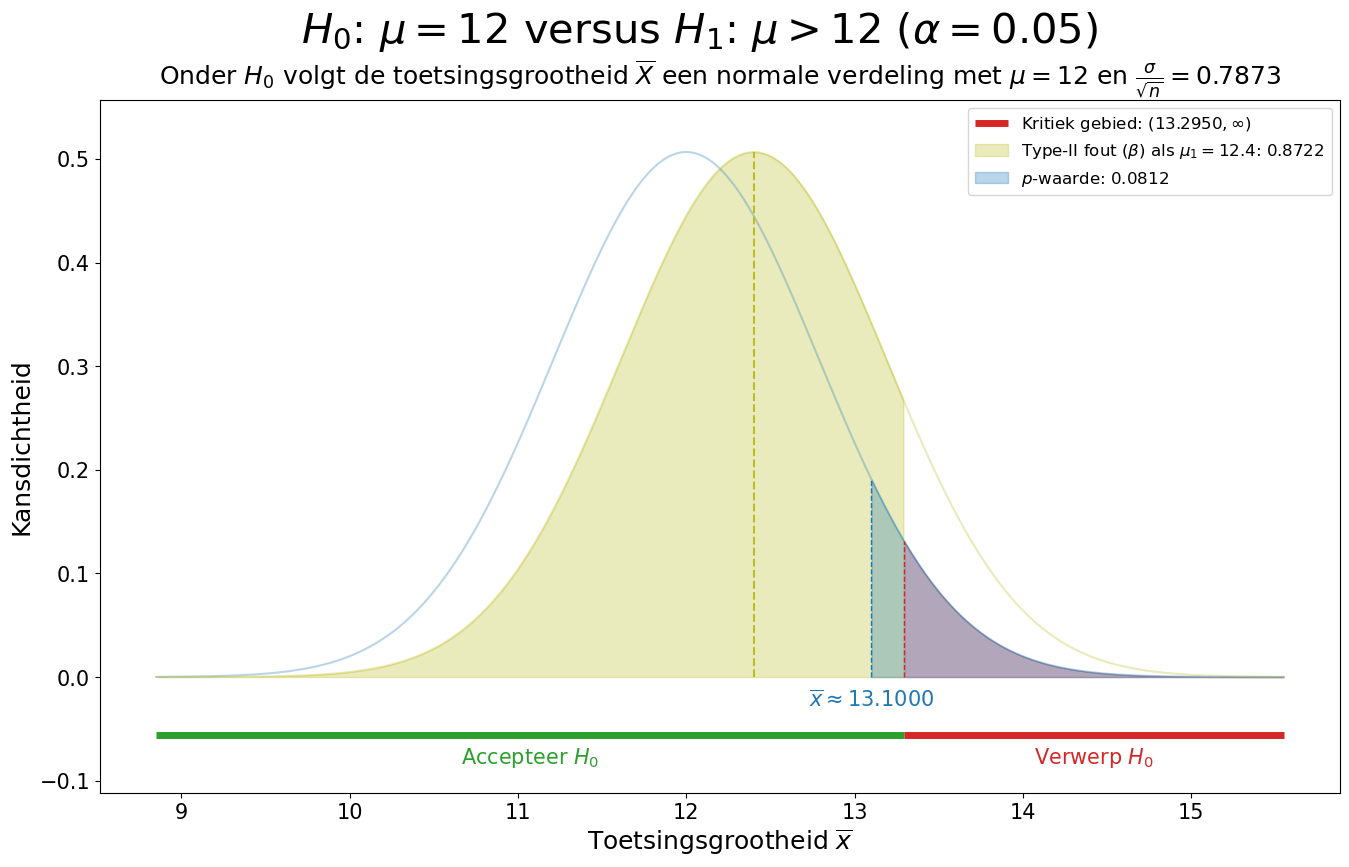

In [64]:
mu_0 = 12
mu_1 = 12.4 # Kan ook None zijn
sample_mean = 13.1
sigma = 4.3123
sample_size = 30
norm_params = {"mu_0": 12, "sample_mean": 13.1, "std_error": sigma / np.sqrt(sample_size), "mu_1": mu_1}

test_statistic = norm_params["sample_mean"]
plot_hypothesis_normal(test_type="rechtszijdig", alpha=0.05, test_statistic=test_statistic, filename="z-test.png", **norm_params)

### 2. $t$-toets voor het gemiddelde $\mu$ van een normale verdeling (geval: $\sigma$ onbekend)

Hierbij moeten een aantal dingen aangegeven worden
- mu_0: gemiddelde onder de nulhypothese
- sample_mean: steekproefgemiddelde
- sample_std: steekproefstandaardafwijking
- sample_size: steekproefgrootte
- test_type (linkszijdig / tweezijdig / rechtszijdig): geeft aan hoe de hypotheses eruit zien en hoe we kijken naar kritieke waarden.

X-range -2.7145885954249196 2.7145885954249196
Y-range 0 0.42683664883613637
X-range -2.7145885954249196 2.7145885954249196
Y-range 0 0.42683664883613637


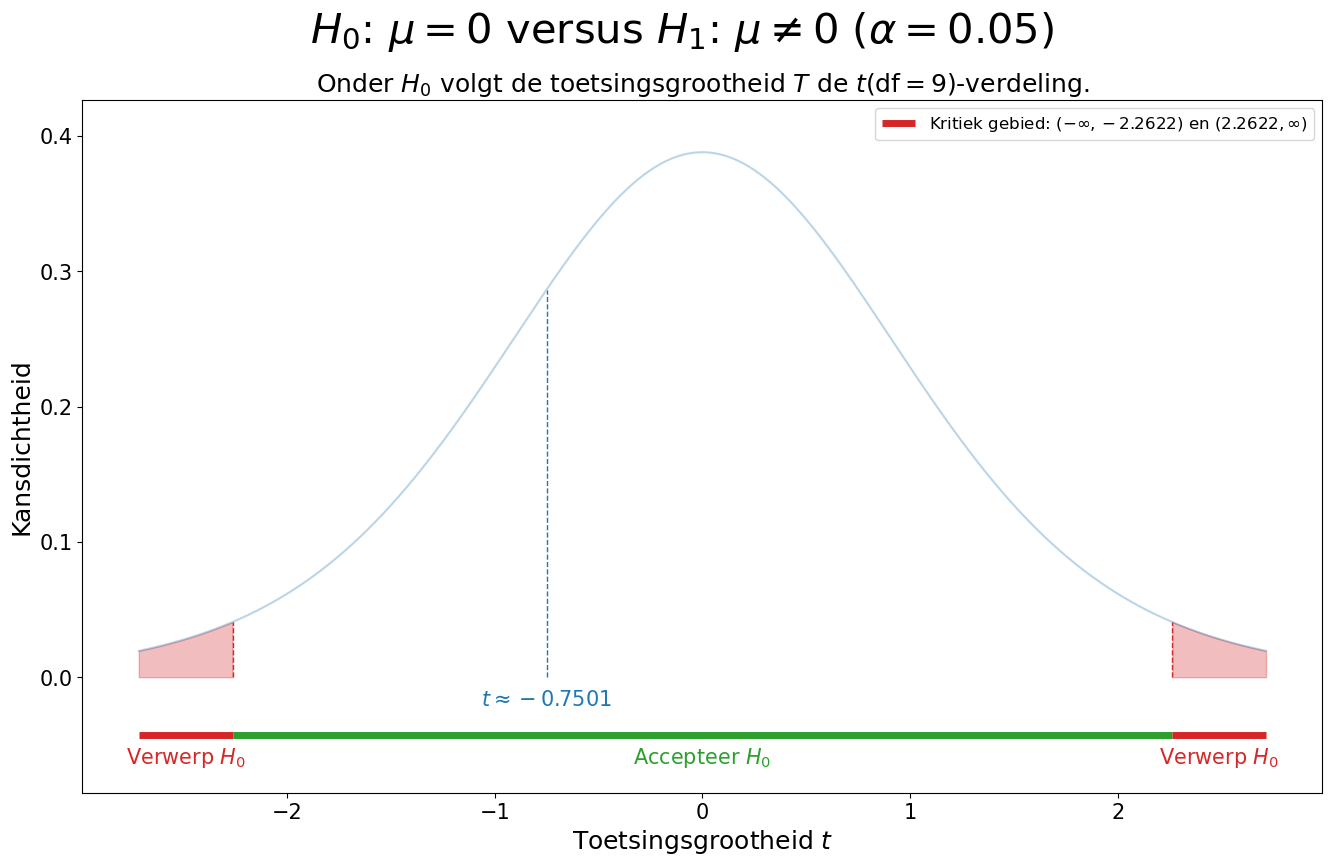

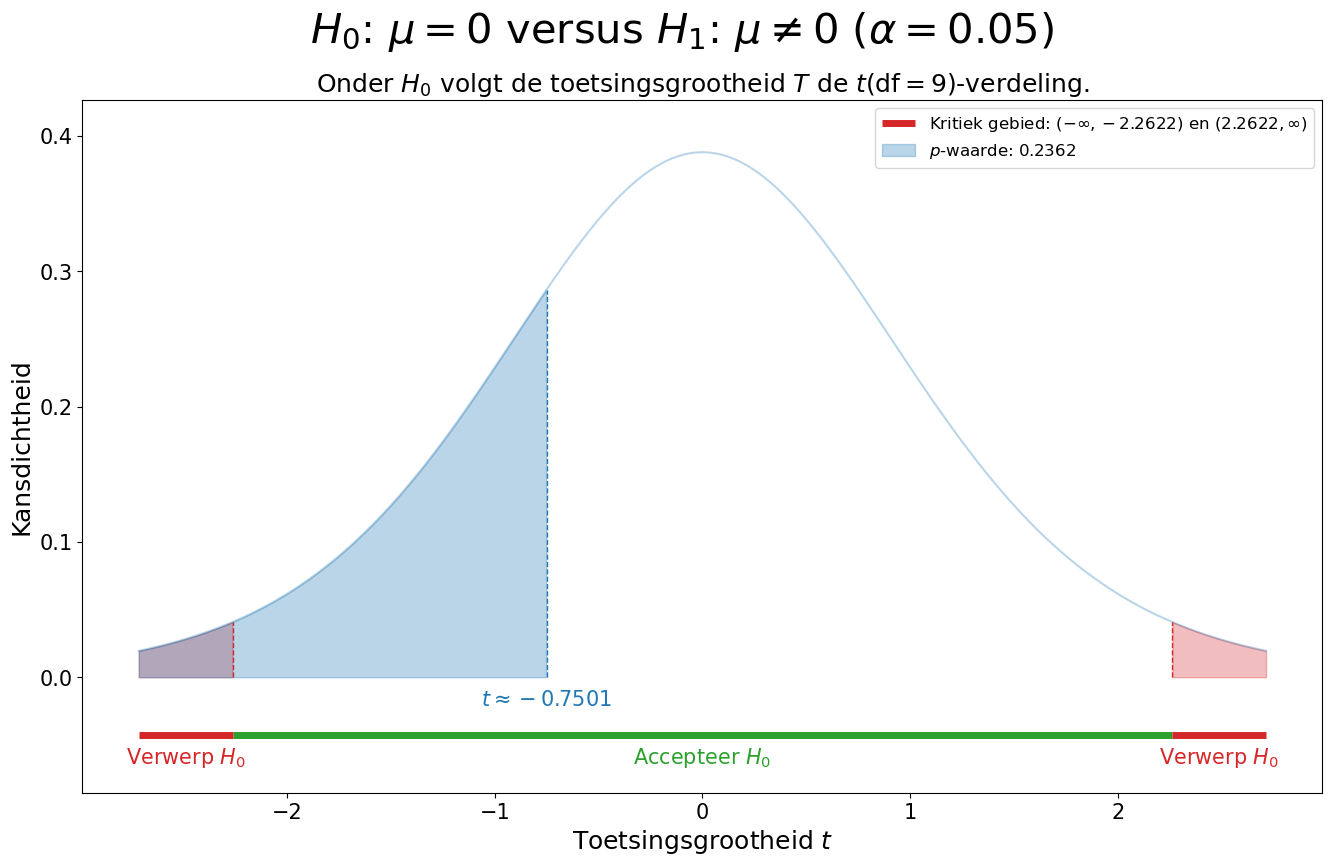

In [71]:
mu_0 = 0
sample_mean = -5
sample_size = 10
t_params = {"mu_0": mu_0, "sample_mean": sample_mean, "std_error": np.sqrt(407.5555/10 + 44.1818/12), "df": sample_size - 1, "num_samples": 1}

test_statistic = (t_params["sample_mean"] - t_params["mu_0"]) / t_params["std_error"]

plot_hypothesis_t(test_type="tweezijdig", alpha=0.05, test_statistic=test_statistic, draw_p_value=False, filename="t-test-critical.png", **t_params)
plot_hypothesis_t(test_type="tweezijdig", alpha=0.05, test_statistic=test_statistic, draw_p_value=True, filename="t-test-pvalue.png", **t_params)

### 3. $t$-toets voor gelijkheid van gemiddelden van twee onafhankelijke populaties

X-range -2.7145885954249196 2.7145885954249196
Y-range 0 0.42683664883613637
X-range -2.7145885954249196 2.7145885954249196
Y-range 0 0.42683664883613637


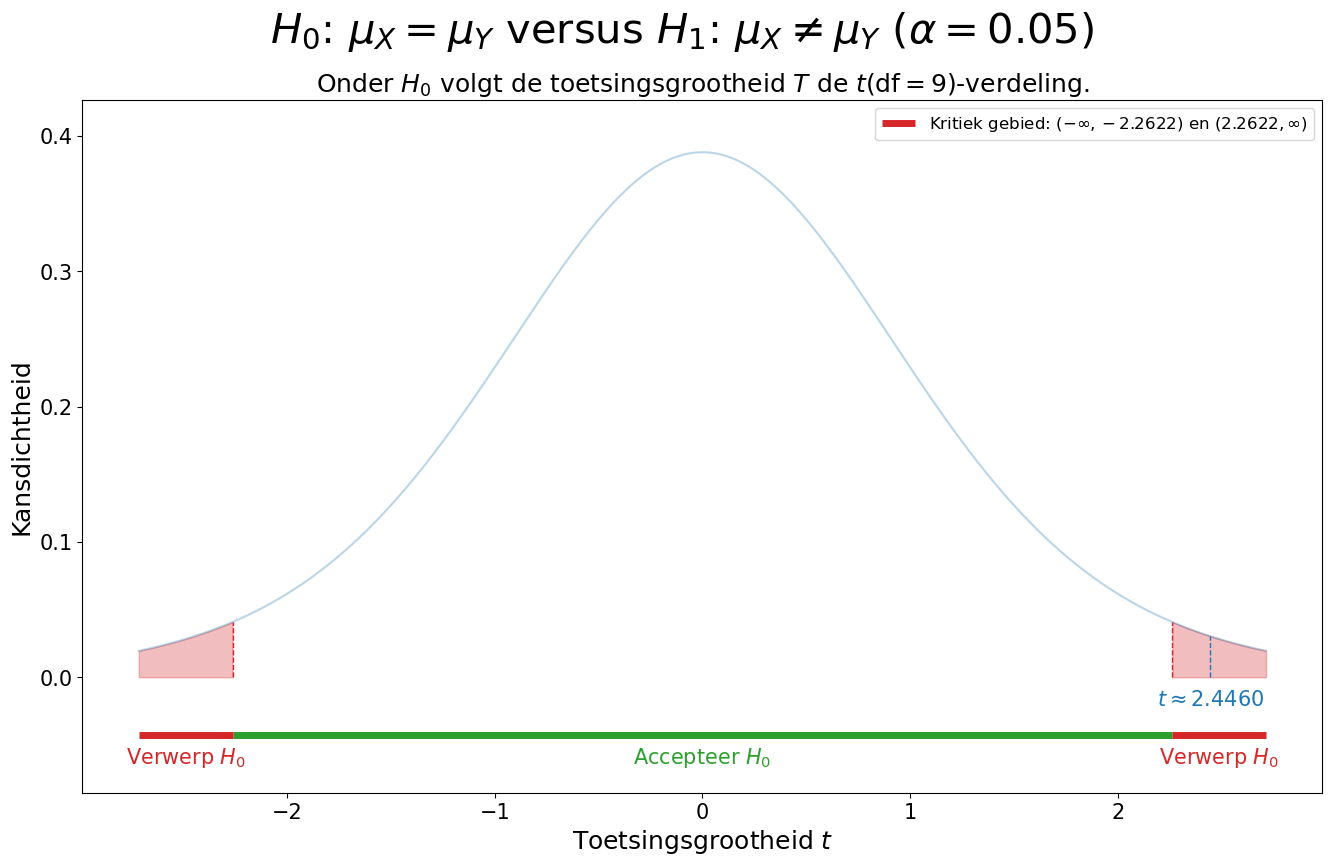

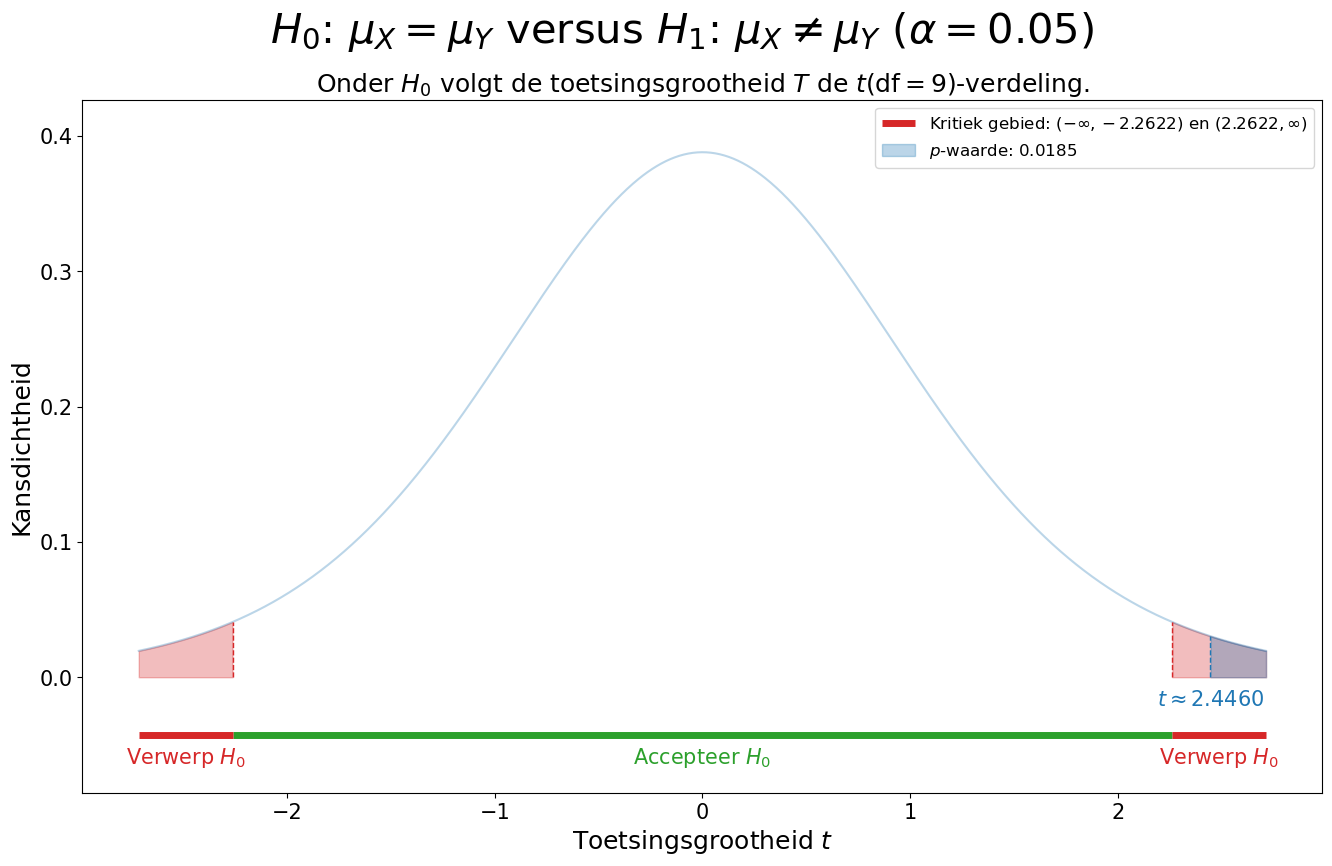

In [74]:
data1 = [12.1, 11.9, 12.3, 11.8, 12.2, 12.0, 11.9, 12.4, 11.7, 12.1, 12.0, 11.8]  # Levertijd leverancier A
data2 = [11.9, 7.3, 14.7, 6.0, 13.6, 8.0, 9.3, 5.0, 7.6, 11.4] # Levertijd leverancier B

sample_mean_1 = np.mean(data1)
sample_mean_2 = np.mean(data2)
sample_var_1 = np.var(data1, ddof=1)
sample_var_2 = np.var(data2, ddof=1)
n1, n2 = len(data1), len(data2)

equal_variance = False

if equal_variance:
    pooled_variance = ((n1 - 1) * sample_var_1 + (n2 - 1) * sample_var_2) / (n1 + n2 - 2)
    std_error = np.sqrt(pooled_variance * (1 / n1 + 1 / n2))
    df = n1 + n2 - 2
else:
    std_error = np.sqrt(sample_var_1 / n1 + sample_var_2 / n2)
    df = min(n1 - 1, n2 - 1)

t_params = {"mu_0": 0, "sample_mean": sample_mean_1 - sample_mean_2, "std_error": std_error, "df": df, "num_samples": 2}
test_statistic = (t_params["sample_mean"] - t_params["mu_0"]) / t_params["std_error"]

plot_hypothesis_t(test_type="tweezijdig", alpha=0.05, test_statistic=test_statistic, draw_p_value=False, filename="two-sample-t-test-critical.png", **t_params)
plot_hypothesis_t(test_type="tweezijdig", alpha=0.05, test_statistic=test_statistic, draw_p_value=True, filename="two-sample-t-test-pvalue.png", **t_params)

### 4. Chikwadraattoetsen

X-range 0 13.284597232219621
Y-range 0 0.1695979626079367
X-range 0 18.60877566703854
Y-range 0 0.12322297415453959


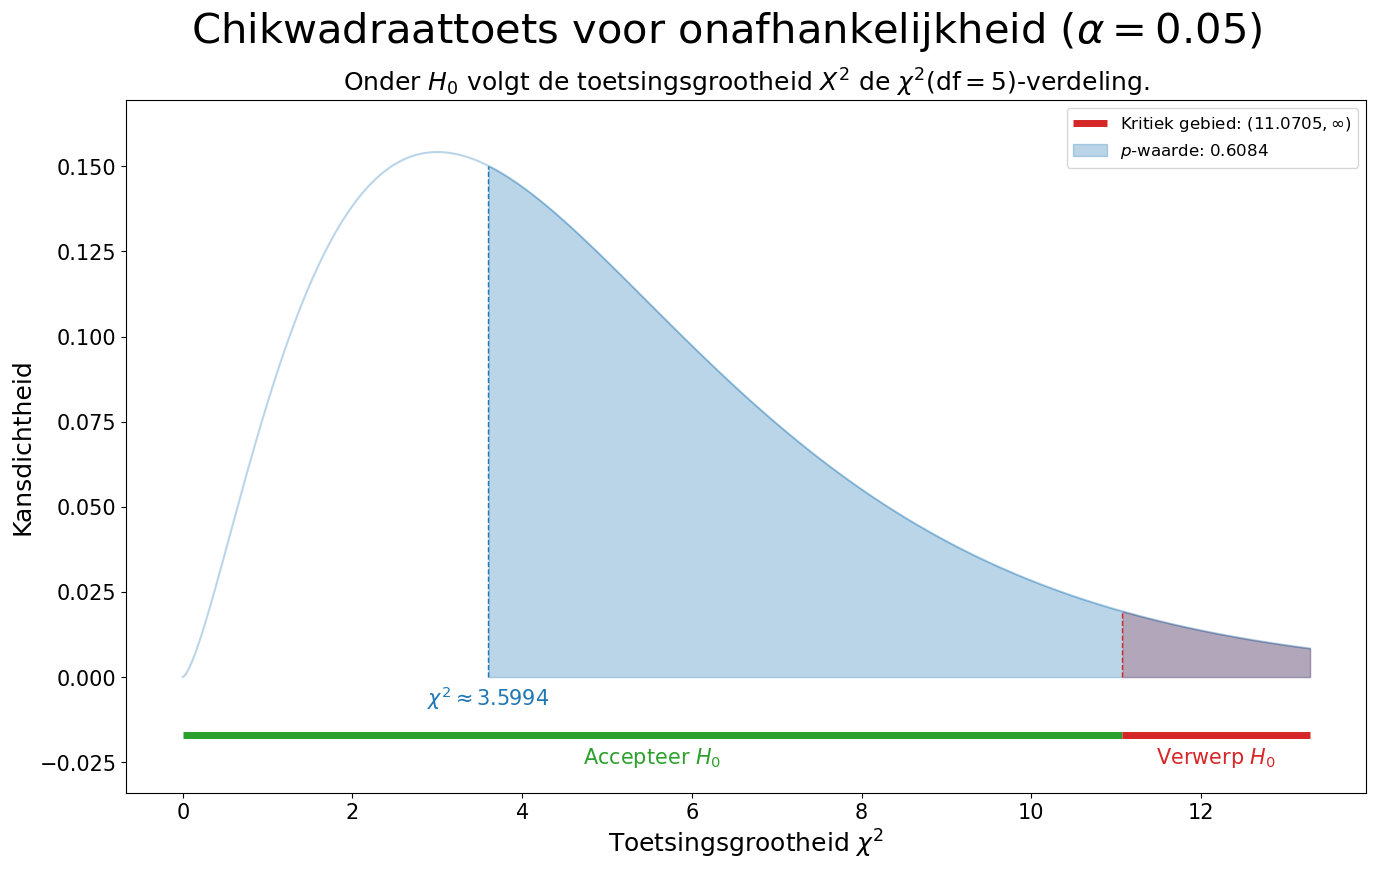

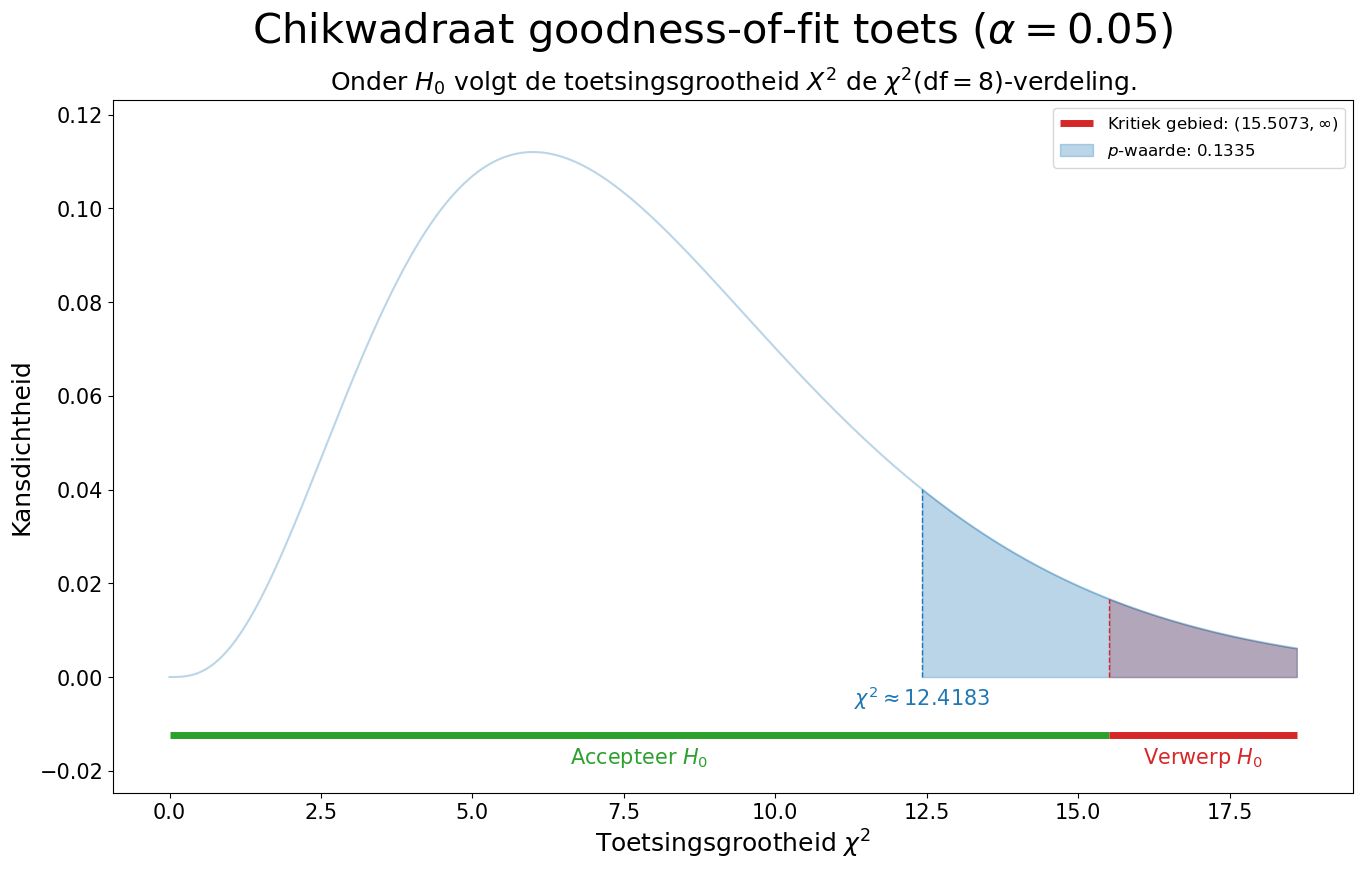

In [83]:
# Chikwadraattoets voor onafhankelijkheid van twee categorische variabelen
sample_size = 6
chi2_indep_params = {"df": sample_size - 1, "type": "onafhankelijkheid"}
test_statistic = 3.5994
plot_hypothesis_chi2(alpha=0.05, test_statistic=test_statistic, filename="chi2-independence-test.png", **chi2_indep_params)

# Chikwadraat goodness-of-fit test
sample_size = 9
chi2_gof_params = {"df": sample_size - 1, "type": "goodness-of-fit"}
test_statistic = 12.4183
plot_hypothesis_chi2(alpha=0.05, test_statistic=test_statistic, filename="exam20260724-chi2-pwaarde.png", **chi2_gof_params)

### 5. $F$-toets voor gelijke varianties van twee onafhankelijke populaties

Eerste steekproefgemiddelde: 12.016666666666666
Tweede steekproefgemiddelde: 9.48
Eerste steekproefvariantie: 0.04515151515151515
Tweede steekproefvariantie: 10.717333333333334
Geobserveerde toetsingsgrootheid: $f pprox 0.00421294306589156
Geobserveerde toetsingsgrootheid: $t pprox 2.3205668192723814
X-range 0 4.694489360721067
Y-range 0 0.8227170282340356


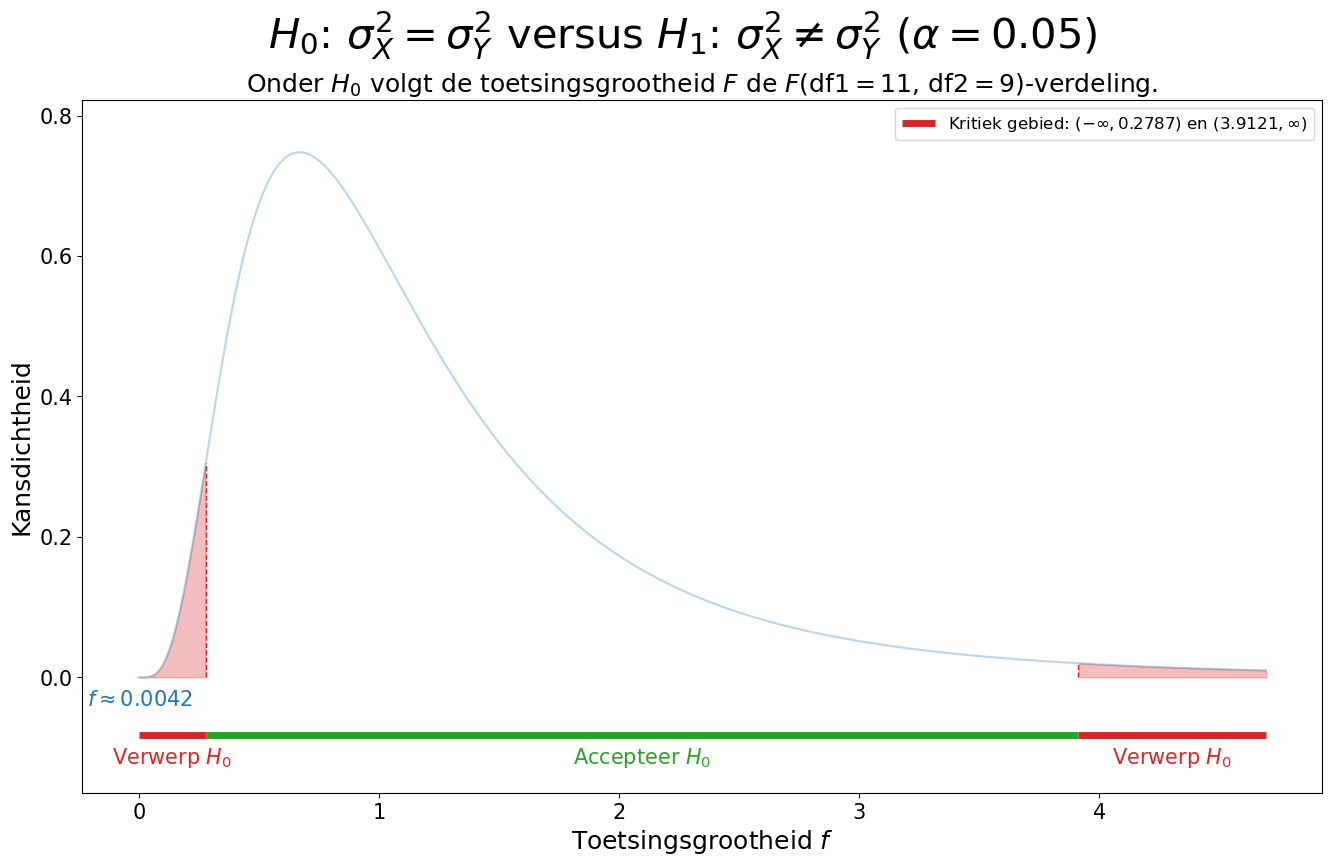

In [86]:
data1 = [12.1, 11.9, 12.3, 11.8, 12.2, 12.0, 11.9, 12.4, 11.7, 12.1, 12.0, 11.8]  # Levertijd leverancier A
data2 = [11.9, 7.3, 14.7, 6.0, 13.6, 8.0, 9.3, 5.0, 7.6, 11.4] # Levertijd leverancier B

F_params = {"dfn": len(data1) - 1, "dfd": len(data2) - 1, "mean_1": np.mean(data1), "variance_1": np.var(data1, ddof=1),
            "mean_2": np.mean(data2), "variance_2": np.var(data2, ddof=1)}
test_statistic = F_params["variance_1"] / F_params["variance_2"]

print(f"Eerste steekproefgemiddelde: {F_params["mean_1"]}")
print(f"Tweede steekproefgemiddelde: {F_params["mean_2"]}")

print(f"Eerste steekproefvariantie: {F_params["variance_1"]}")
print(f"Tweede steekproefvariantie: {F_params["variance_2"]}")

F_test_statistic = F_params["variance_1"]  / F_params["variance_2"]
print(f"Geobserveerde toetsingsgrootheid: $f \approx {F_test_statistic}")
equal_variances = False

if not equal_variances:
    t_test_statistic = ((F_params["mean_1"] - F_params["mean_2"]) - 0) / np.sqrt(F_params["variance_1"] / F_params["dfn"] + F_params["variance_2"] / F_params["dfd"])
    print(f"Geobserveerde toetsingsgrootheid: $t \approx {t_test_statistic}")

plot_hypothesis_f(alpha=0.05, test_statistic=test_statistic, draw_p_value=False, filename="exam20260724-f-kritiek.png", **F_params)